# 01b — Bổ sung khảo sát dữ liệu & bảng chất lượng dữ liệu

Bổ sung cho notebook 01 theo bộ tiêu chí Bài kiểm tra 1:

| Mục | Nội dung | Tiêu chí |
|---|---|---|
| 1 | Chạy lại **đúng mã làm sạch** của notebook 01 trên bản thô đã lưu, đồng thời **đếm** từng loại vấn đề | #6 |
| 2 | **Bảng thống kê vấn đề chất lượng dữ liệu** (thiếu, trùng, ngoại lai, sai định dạng, mất cân bằng, **rò rỉ dữ liệu**) + cách xử lý + lý do | #6, #7 |
| 3 | **So sánh trước – sau xử lý** (bảng + biểu đồ) | #7 |
| 4 | **Phân bố các đặc trưng chính và nhãn**, mỗi biểu đồ có nhận xét | #4 |
| 5 | **Quan hệ đặc trưng – nhãn**, nhận xét cho xây dựng mô hình | #5 |

Đầu vào trên Drive: `data_processed/01_hanoi_nhapho_raw.parquet`, `02_hanoi_nhapho_clean.parquet`, `survey/00_pheu_loc_du_lieu.csv`.
Đầu ra: `survey/01b/`, `figures/01b/`. **Không** ghi đè kết quả của notebook 01.

## 0. Cấu hình & hàm tiện ích (giống notebook 01)

In [1]:
import os, re, json, glob, unicodedata, warnings
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Chạy trên Colab:", IN_COLAB)

Chạy trên Colab: False


In [2]:
# ===================== CẤU HÌNH =====================
def find_project_dir():
    # Thứ tự ưu tiên: (1) biến môi trường ML_PROJECT_DIR; (2) Colab: thư mục dự án trên Google Drive;
    # (3) chạy trên máy: thư mục gốc dự án (nơi có requirements.txt) — thư mục hiện tại hoặc thư mục cha
    if os.environ.get("ML_PROJECT_DIR"):
        return os.environ["ML_PROJECT_DIR"]
    if IN_COLAB:
        return "/content/drive/MyDrive/ML_house_price"
    here = os.path.abspath(os.getcwd())
    for p in (here, os.path.dirname(here)):
        if os.path.isfile(os.path.join(p, "requirements.txt")):
            return p
    return here

PROJECT_DIR = find_project_dir()
OUT_DIR    = f"{PROJECT_DIR}/data_processed"
SURVEY_DIR = f"{PROJECT_DIR}/survey"
FIG_DIR    = f"{PROJECT_DIR}/figures"

# Nguồn dữ liệu: "hf" = tải từ Hugging Face; "drive" = đọc shard parquet đã có sẵn trên Drive
DATA_SOURCE   = "hf"
HF_REPO       = "tinixai/vietnam-real-estates"
# Colab: ổ đĩa tạm /content (nhanh, không tốn dung lượng Drive); trên máy: thư mục raw_parquet/ trong dự án (đã .gitignore)
LOCAL_RAW_DIR = "/content/raw_parquet" if IN_COLAB else f"{PROJECT_DIR}/raw_parquet"
DRIVE_RAW_DIR = f"{PROJECT_DIR}/raw_parquet"     # dùng khi DATA_SOURCE = "drive"

# Nếu tự dò tên cột sai, ghi đè ở đây, ví dụ: {"type": "category_name", "date": "created_at"}
COL_OVERRIDE = {}

# Phạm vi
PROVINCE_KEYWORD = "ha noi"   # so khớp trên tên tỉnh đã bỏ dấu, viết thường
# Loại hình giữ lại / loại bỏ (regex trên chuỗi đã bỏ dấu, viết thường) — xem bảng ở bước 3 rồi chỉnh
# Dữ liệu thật dùng nhãn chung "Nhà" (gồm nhà riêng, nhà phố, nhà trong ngõ) → phải khớp cả "nha" đứng một mình
KEEP_TYPE_RE    = r"^nha$|\bnha\s+(?:rieng|pho|mat\s+pho|mat\s+tien|mat\s+duong|ngo|hem|trong\s+ngo|trong\s+hem)\b"
EXCLUDE_TYPE_RE = (r"chung\s+cu|can\s+ho|biet\s+thu|lien\s+ke|shophouse|condotel|dat\s+nen|^dat\b|\bban\s+dat\b"
                   r"|\bkho\b|xuong|van\s+phong|phong\s+tro|nha\s+tro|khach\s+san|trang\s+trai|mat\s+bang|cho\s+thue")

# Ngưỡng hợp lý cho nhà riêng/nhà phố Hà Nội (giải thích trong báo cáo)
PRICE_MIN, PRICE_MAX = 3e8, 3e11      # 300 triệu – 300 tỷ VND
AREA_MIN,  AREA_MAX  = 10, 1000       # m²
UNIT_MIN,  UNIT_MAX  = 5e6, 2e9       # 5 triệu – 2 tỷ VND/m²
# Giá trị ngoài khoảng → đặt NaN (không xoá dòng); sẽ được điền ở pipeline huấn luyện
PLAUSIBLE = {
    "floor_count":    (1, 15),
    "bedroom_count":  (1, 30),
    "bathroom_count": (1, 30),
    "frontage_width": (1, 50),    # m
    "house_depth":    (2, 200),   # m
    "road_width":     (0.5, 100), # m
}
HANOI_BBOX = (20.5, 21.45, 105.25, 106.05)   # lat_min, lat_max, lon_min, lon_max
CENTER     = (21.0285, 105.8542)             # Hồ Gươm

MIN_FEATURE_COVERAGE = 0.10   # đặc trưng số có dữ liệu ở < 10% số tin thì bỏ (không đủ thông tin để điền)
ROBUST_Z   = 3.5   # ngưỡng robust z-score của log(đơn giá) trong cùng phường
MIN_WARD_N = 20    # phường có ít tin hơn → so với phân phối toàn thành phố
TEST_SIZE, SEED = 0.2, 42

# File ánh xạ địa chỉ cũ → mới (đầu ra của module NLP), tuỳ chọn.
# Cột yêu cầu: district_key, ward_key, ward_new  (khoá = tên đã bỏ dấu, bỏ tiền tố "phường/quận")
ADDRESS_MAPPING_CSV = f"{PROJECT_DIR}/address_mapping.csv"

for d in [OUT_DIR, SURVEY_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
print("Lưu kết quả vào:", PROJECT_DIR)

Lưu kết quả vào: D:\HocMay_GiaNha_KT1


In [3]:
def strip_accents(s: str) -> str:
    s = unicodedata.normalize("NFD", s)
    s = "".join(ch for ch in s if unicodedata.category(ch) != "Mn")
    return s.replace("đ", "d").replace("Đ", "D")

def norm_key(x) -> str:
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return ""
    s = strip_accents(str(x)).lower()
    return re.sub(r"[^a-z0-9]+", " ", s).strip()

def map_unique(s: pd.Series, func) -> pd.Series:
    # Áp func lên giá trị duy nhất rồi map lại — nhanh hơn apply trên hàng trăm nghìn dòng
    uniq = s.dropna().unique()
    return s.map(dict(zip(uniq, [func(u) for u in uniq])))

def keys_of(s: pd.Series) -> pd.Series:
    return map_unique(s, norm_key).fillna("").astype(str)

NUM_RE = re.compile(r"\d+(?:[.,]\d+)*")

def to_float_vn(tok: str) -> float:
    tok = tok.strip()
    if "," in tok and "." in tok:
        # dấu xuất hiện sau cùng là dấu thập phân
        tok = tok.replace(".", "").replace(",", ".") if tok.rfind(",") > tok.rfind(".") else tok.replace(",", "")
    else:
        sep = "," if "," in tok else ("." if "." in tok else None)
        if sep:
            parts = tok.split(sep)
            if len(parts) > 2 or (len(parts[-1]) == 3 and parts[0] != "0"):
                tok = tok.replace(sep, "")      # phân cách hàng nghìn
            else:
                tok = tok.replace(sep, ".")     # dấu thập phân
    try:
        return float(tok)
    except ValueError:
        return np.nan

def parse_number(x) -> float:
    if x is None:
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)
    m = NUM_RE.search(str(x))
    return to_float_vn(m.group()) if m else np.nan

def to_numeric_col(s: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return map_unique(s, parse_number).astype(float)

PRICE_UNITS = {"ty": 1e9, "trieu": 1e6, "tr": 1e6, "nghin": 1e3, "ngan": 1e3, "k": 1e3}
PRICE_TOKEN_RE = re.compile(r"(\d+(?:[.,]\d+)*)\s*(ty|trieu|tr|nghin|ngan|k)?(?![a-z])")

def parse_price(x):
    # Trả về (giá VND, cờ "giá theo m²")
    if x is None:
        return (np.nan, False)
    if isinstance(x, (int, float, np.integer, np.floating)):
        return (np.nan, False) if pd.isna(x) else (float(x), False)
    s = strip_accents(str(x)).lower().strip()
    if not s or re.search(r"thoa\s*thuan|lien\s*he|deal", s):
        return (np.nan, False)
    per_m2 = bool(re.search(r"/\s*m", s))
    tokens = PRICE_TOKEN_RE.findall(s)
    if not tokens:
        return (np.nan, per_m2)
    if not any(u for _, u in tokens):
        return (to_float_vn(tokens[0][0]), per_m2)
    total, prev_unit = 0.0, None
    for num, unit in tokens:
        v = to_float_vn(num)
        if np.isnan(v):
            continue
        if unit:
            total += v * PRICE_UNITS[unit]
            prev_unit = unit
        elif prev_unit == "ty" and v < 1000:   # "8 tỷ 500" = 8 tỷ 500 triệu
            total += v * 1e6
            prev_unit = None
    return (total if total > 0 else np.nan, per_m2)

def parse_price_col(s: pd.Series):
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float), pd.Series(False, index=s.index)
    parsed = {u: parse_price(u) for u in s.dropna().unique()}
    val = s.map({k: v[0] for k, v in parsed.items()}).astype(float)
    pm2 = s.map({k: v[1] for k, v in parsed.items()}).eq(True)
    return val, pm2

def find_col(cols, candidates):
    low = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in low:
            return low[cand.lower()]
    return None

FUNNEL = []
def log_step(step, n, note=""):
    prev = FUNNEL[-1]["rows"] if FUNNEL else None
    FUNNEL.append({"step": step, "rows": int(n),
                   "removed": 0 if prev is None else int(prev - n), "note": note})
    print(f"[{step}] {n:,} dòng" + ("" if prev is None else f"  (−{prev - n:,})") + (f" — {note}" if note else ""))

def save_df(df, name, csv=False):
    path = os.path.join(OUT_DIR, f"{name}.parquet")
    df.to_parquet(path, index=False)
    if csv:
        df.to_csv(path[:-8] + ".csv", index=False, encoding="utf-8-sig")
    print("Đã lưu:", path, df.shape)

def save_table(df, name):
    path = os.path.join(SURVEY_DIR, f"{name}.csv")
    df.to_csv(path, encoding="utf-8-sig")
    print("Đã lưu:", path)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# quick self-test
assert parse_price("8,5 tỷ")[0] == 8.5e9
assert parse_price("850 triệu")[0] == 8.5e8
assert parse_price("8 tỷ 500")[0] == 8.5e9
assert parse_price("120 triệu/m²") == (1.2e8, True)
assert np.isnan(parse_price("Thỏa thuận")[0])
assert parse_price("8500000000")[0] == 8.5e9
assert to_float_vn("1.234.567") == 1234567 and to_float_vn("98,5") == 98.5
print("Hàm tiện ích OK")

Hàm tiện ích OK


In [4]:
# Kết quả của notebook này ghi vào thư mục con riêng, không ghi đè notebook 01
SURVEY_DIR, FIG_DIR = f"{PROJECT_DIR}/survey/01b", f"{PROJECT_DIR}/figures/01b"
for d in [SURVEY_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
TEXT_FLAGS = ["has_so_do", "car_access", "is_mat_pho", "kinh_doanh", "lo_goc", "no_hau", "thang_may"]

def missing_table(frame):
    m = frame.isna() | frame.astype(str).apply(lambda s: s.str.strip().isin(["", "nan", "None"]))
    return (m.mean() * 100).round(2).sort_values(ascending=False).rename("thieu_%").to_frame()

raw = pd.read_parquet(os.path.join(OUT_DIR, "01_hanoi_nhapho_raw.parquet"))
clean = pd.read_parquet(os.path.join(OUT_DIR, "02_hanoi_nhapho_clean.parquet"))
funnel0 = pd.read_csv(f"{PROJECT_DIR}/survey/00_pheu_loc_du_lieu.csv", encoding="utf-8-sig")
print(f"Bản thô (Hà Nội + loại hình 'Nhà'): {len(raw):,} dòng | bản sạch: {len(clean):,} dòng")

FUNNEL.clear()
for _, r in funnel0.iloc[:3].iterrows():           # 3 bước đầu (toàn bộ → Hà Nội → loại hình) lấy từ notebook 01
    FUNNEL.append({"step": r["step"], "rows": int(r["rows"]), "removed": int(r["removed"]), "note": str(r.get("note", ""))})
df = raw.copy()
ISSUES = []        # (nhóm vấn đề, vấn đề, số bản ghi, mẫu số, cách xử lý, lý do)
def issue(group, name, n, base, how, why):
    ISSUES.append({"nhóm": group, "vấn đề": name, "số bản ghi": int(n), "tỷ lệ (%)": round(100 * n / base, 2) if base else np.nan,
                   "cách xử lý": how, "lý do": why})

Bản thô (Hà Nội + loại hình 'Nhà'): 549,408 dòng | bản sạch: 390,169 dòng


## 1. Chạy lại các bước làm sạch của notebook 01 và đếm vấn đề
Các ô dưới đây là **nguyên văn** mã của notebook 01 (bước 6 → 10), xen giữa là các ô đếm.

In [5]:
# Sai định dạng: giá lưu dạng chuỗi
N0 = len(df)
price_is_text = df["price"].map(lambda v: isinstance(v, str) and not re.fullmatch(r"\s*\d+(\.\d+)?\s*", v))
issue("Sai định dạng", "Giá lưu dạng chữ (\"8,5 tỷ\", \"850 triệu\"…) thay vì số", price_is_text.sum(), N0,
      "Parse bằng hàm parse_price (tỷ/triệu/nghìn, dấu thập phân kiểu Việt Nam)", "Dataset card khai báo float64 nhưng thực tế là chuỗi")

In [6]:
df["price_raw"] = df["price"].astype(str)
for c in ["area", "floor_count", "frontage_width", "house_depth", "road_width",
          "bedroom_count", "bathroom_count", "lat", "lon"]:
    df[c] = to_numeric_col(df[c])

val, pm2 = parse_price_col(df["price"])
df["price"] = np.where(pm2 & df["area"].gt(0), val * df["area"], val)
print(f"Giá theo m² đã quy đổi: {int(pm2.sum()):,} tin | giá không đọc được/thỏa thuận: {int(np.isnan(val).sum()):,} tin")

def to_datetime_col(s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return s
    if pd.api.types.is_numeric_dtype(s):       # epoch giây hoặc mili-giây
        unit = "ms" if s.dropna().median() > 1e11 else "s"
        return pd.to_datetime(s, unit=unit, errors="coerce")
    return pd.to_datetime(s, errors="coerce")

df["date"] = to_datetime_col(df["date"])
if hasattr(df["date"].dt, "tz") and df["date"].dt.tz is not None:
    df["date"] = df["date"].dt.tz_localize(None)
print("Khoảng ngày đăng:", df["date"].min(), "→", df["date"].max())
display(df[["price_raw", "price", "area"]].sample(min(10, len(df)), random_state=SEED))

Giá theo m² đã quy đổi: 0 tin | giá không đọc được/thỏa thuận: 16,021 tin


Khoảng ngày đăng: 2025-06-01 00:18:52.602000 → 2026-03-30 23:58:16.386000


,price_raw,price,area
201027,34900000000,3.490000e+10,80.0
49052,15800000000,1.580000e+10,45.0
109492,9300000000,9.300000e+09,35.0
483730,8400000000,8.400000e+09,56.0
187179,12000000000,1.200000e+10,60.0
178348,17500000000,1.750000e+10,64.0
272015,19000000000,1.900000e+10,60.0
467772,15700000000,1.570000e+10,48.0
368711,13000000000,1.300000e+10,54.0
353442,None,NaN,40.0


In [7]:
issue("Thiếu / không dùng được", "Giá không đọc được, \"Thỏa thuận\", \"Liên hệ\" hoặc trống", int(np.isnan(val).sum()), N0,
      "Loại bỏ", "Không có nhãn thì không huấn luyện/đánh giá được; điền giá sẽ tạo nhãn giả")
issue("Sai định dạng", "Giá ghi theo m² (\"120 triệu/m²\")", int(pm2.sum()), N0, "Nhân với diện tích", "Đưa về cùng đơn vị tổng giá VND")
before = df.copy()      # ảnh chụp "trước xử lý" (đã parse, chưa lọc)

In [8]:
# Tiền tố tách riêng cho phường và quận: nếu dùng chung, tên phường "Quan Hoa", "Quán Thánh"
# sẽ bị cắt nhầm chữ "quan" thành "hoa", "thanh"
WARD_PREFIX_RE     = r"^(?:phuong|xa|thi\s+tran|p|x|tt)\s+"
DISTRICT_PREFIX_RE = r"^(?:quan|huyen|thi\s+xa|thanh\s+pho|tp|q|h|tx)\s+"

def admin_key(s, prefix_re):
    return keys_of(s).str.replace(prefix_re, "", regex=True).str.strip()

df["district_key"] = admin_key(df["district"], DISTRICT_PREFIX_RE)
df["ward_key"]     = admin_key(df["ward"], WARD_PREFIX_RE)
df["street_key"]   = keys_of(df["street"]).str.replace(r"^(?:duong|pho|ngo|ngach|hem)\s+", "", regex=True)

def normalize_to_new_units(frame):
    # TODO: thay bằng module chuẩn hoá địa chỉ cũ → mới (đề tài NLP) nếu muốn gọi trực tiếp
    if os.path.exists(ADDRESS_MAPPING_CSV):
        mp = pd.read_csv(ADDRESS_MAPPING_CSV, dtype=str)[["district_key", "ward_key", "ward_new"]].drop_duplicates(
            ["district_key", "ward_key"])
        frame = frame.merge(mp, on=["district_key", "ward_key"], how="left")
        n_miss = frame["ward_new"].isna().sum()
        print(f"Đã ghép address_mapping.csv — {n_miss:,} tin chưa ánh xạ được (giữ ward_key cũ)")
        frame["ward_new"] = frame["ward_new"].fillna(frame["ward_key"])
    else:
        print("Chưa có address_mapping.csv → tạm dùng ward_key (đơn vị cũ) làm ward_new")
        frame["ward_new"] = frame["ward_key"]
    frame["ward_new"] = frame["ward_new"].replace("", "unknown")
    return frame

df = normalize_to_new_units(df)
print(f"Số quận/huyện (cũ): {df['district_key'].nunique():,} | số phường/xã: {df['ward_new'].nunique():,}")

# Xuất danh sách (quận, phường) duy nhất để chạy qua module NLP rồi tạo address_mapping.csv
uniq_addr = (df.groupby(["district_key", "ward_key"]).size().rename("so_tin").reset_index()
               .sort_values("so_tin", ascending=False))
save_table(uniq_addr.set_index(["district_key", "ward_key"]), "05_danh_sach_dia_chi_can_chuan_hoa")

Chưa có address_mapping.csv → tạm dùng ward_key (đơn vị cũ) làm ward_new
Số quận/huyện (cũ): 30 | số phường/xã: 427
Đã lưu: D:\HocMay_GiaNha_KT1/survey/01b\05_danh_sach_dia_chi_can_chuan_hoa.csv


In [9]:
n_dist_raw = df["district"].astype(str).str.strip().nunique()
n_dist_key = df["district_key"].nunique()
if n_dist_raw > n_dist_key:
  issue("Sai định dạng", f"Tên quận/huyện không thống nhất: {n_dist_raw} cách ghi → {n_dist_key} khoá chuẩn hoá", n_dist_raw - n_dist_key, n_dist_raw,
      "Bỏ dấu, viết thường, bỏ tiền tố \"Quận/Huyện\"; phường dùng tiền tố riêng", "\"Quận 8\" và \"8\" phải là cùng một giá trị")

In [10]:
def fix_price_scale(price, area):
    out, mult = price.copy(), pd.Series(1.0, index=price.index)
    bad = price.notna() & (price < PRICE_MIN) & area.gt(0)
    for m in [1e3, 1e6, 1e9]:
        cand = bad & mult.eq(1) & (price * m / area).between(UNIT_MIN, UNIT_MAX) & (price * m).between(PRICE_MIN, PRICE_MAX)
        out[cand], mult[cand] = price[cand] * m, m
    return out, mult

df["price"], scale_mult = fix_price_scale(df["price"], df["area"])
print("Số tin đã sửa đơn vị giá:", scale_mult.value_counts().drop(1.0, errors="ignore").to_dict())

valid = df["price"].gt(0) & df["area"].gt(0)
df = df[valid].reset_index(drop=True)
log_step("Có giá & diện tích hợp lệ", len(df), "loại giá thỏa thuận/không đọc được, diện tích thiếu")

Số tin đã sửa đơn vị giá: {1000.0: 183}


[Có giá & diện tích hợp lệ] 530,093 dòng  (−19,315) — loại giá thỏa thuận/không đọc được, diện tích thiếu


In [11]:
for m_, lab in [(1e3, "nghìn"), (1e6, "triệu"), (1e9, "tỷ")]:
    n = int((scale_mult == m_).sum())
    if n:
        issue("Sai định dạng", f"Giá lưu nhầm đơn vị ({lab} đồng) — đã nhân ×{m_:.0e}", n, N0,
              "Nhân hệ số nhỏ nhất đưa đơn giá về khoảng hợp lý", "Ví dụ ghi \"10 tỷ\" nhưng lưu 10.000.000")
issue("Thiếu / không dùng được", "Tổng số tin bị loại vì thiếu giá hoặc diện tích (gồm cả dòng 'giá không đọc được')", N0 - len(df), N0,
      "Loại bỏ", "Thiếu nhãn hoặc đặc trưng chính")

# Rò rỉ do tin đăng lại: NẾU không khử trùng lặp mà chia ngẫu nhiên 80/20 thì bao nhiêu tin test có bản sao ở train?
key = np.where(df["desc_len"].fillna(0) >= 50, df["desc_hash"].astype(str),
               df["ward_key"] + "|" + df["street_key"] + "|" + df["area"].round(1).astype(str) + "|" + (df["price"] / 1e6).round().astype(str))
sim_test = np.random.default_rng(SEED).random(len(df)) < TEST_SIZE
g = pd.DataFrame({"k": key, "test": sim_test})
in_train = set(g.loc[~g["test"], "k"])
leak = int(g.loc[g["test"], "k"].isin(in_train).sum())
issue("Rò rỉ dữ liệu", "Nếu KHÔNG khử trùng lặp: tin ở tập test có bản sao y hệt ở tập train", leak, int(sim_test.sum()),
      "Khử trùng lặp TRƯỚC khi chia train/test", "Mô hình 'đoán đúng' vì đã thấy tin đó → MAE/RMSE đẹp giả tạo")
n_valid = len(df)

In [12]:
df = df.sort_values("date", ascending=False, na_position="last").reset_index(drop=True)

if "id" in df:
    df = df.drop_duplicates("id")
    log_step("Khử trùng id", len(df))

long_desc = df["desc_len"].fillna(0).ge(50)
# mô tả giống hệt nhau → cùng mã băm; chỉ xét mô tả đủ dài để tránh gộp nhầm các mô tả ngắn/rỗng
dup_desc = (long_desc & df["desc_hash"].duplicated(keep="first")).to_numpy(dtype=bool)
df = df.loc[~dup_desc]
log_step("Khử trùng nội dung mô tả", len(df))

df["_area_r"] = df["area"].round(1)
df["_price_r"] = (df["price"] / 1e6).round()
attr_key = ["ward_key", "street_key", "_area_r", "_price_r", "bedroom_count", "floor_count"]
df = df.drop_duplicates(attr_key).drop(columns=["_area_r", "_price_r"]).reset_index(drop=True)
log_step("Khử trùng bộ thuộc tính", len(df))

# Gán train/test NGAY SAU khử trùng lặp, trước mọi thống kê học từ dữ liệu (ngoại lai cục bộ ở mục 10c chỉ học từ train)
rng = np.random.default_rng(SEED)
df["split"] = np.where(rng.random(len(df)) < TEST_SIZE, "test", "train")
log_step("Gán train/test (sau khử trùng lặp)", len(df), f"train {df['split'].eq('train').sum():,} / test {df['split'].eq('test').sum():,}")

[Khử trùng nội dung mô tả] 462,756 dòng  (−67,337)


[Khử trùng bộ thuộc tính] 396,523 dòng  (−66,233)
[Gán train/test (sau khử trùng lặp)] 396,523 dòng  (−0) — train 317,156 / test 79,367


In [13]:
f = pd.DataFrame(FUNNEL).set_index("step")
issue("Trùng lặp", "Tin đăng lại: trùng nội dung mô tả (≥ 50 ký tự)", f.loc["Khử trùng nội dung mô tả", "removed"], n_valid,
      "Giữ tin mới nhất, bỏ phần còn lại", "Cùng một căn nhà đăng nhiều lần")
issue("Trùng lặp", "Tin đăng lại: trùng phường + đường + diện tích + giá + phòng ngủ + số tầng", f.loc["Khử trùng bộ thuộc tính", "removed"], n_valid,
      "Giữ tin mới nhất", "Đăng lại với mô tả khác nhưng cùng căn")
n_dedup = len(df)

In [14]:
df["unit_price"] = df["price"] / df["area"]

df = df[df["price"].between(PRICE_MIN, PRICE_MAX)]
log_step("Ngưỡng giá", len(df), f"{PRICE_MIN/1e9:g}–{PRICE_MAX/1e9:g} tỷ")
df = df[df["area"].between(AREA_MIN, AREA_MAX)]
log_step("Ngưỡng diện tích", len(df), f"{AREA_MIN}–{AREA_MAX} m²")
df = df[df["unit_price"].between(UNIT_MIN, UNIT_MAX)]
log_step("Ngưỡng đơn giá", len(df), f"{UNIT_MIN/1e6:g}–{UNIT_MAX/1e6:g} triệu/m²")

# (b) giá trị phi lý → NaN
rows = []
for c, (lo, hi) in PLAUSIBLE.items():
    bad = df[c].notna() & ~df[c].between(lo, hi)
    rows.append({"cot": c, "khoang_hop_ly": f"[{lo}, {hi}]", "so_gia_tri_dat_NaN": int(bad.sum())})
    df.loc[bad, c] = np.nan
lat_lo, lat_hi, lon_lo, lon_hi = HANOI_BBOX
bad_geo = df["lat"].notna() & ~(df["lat"].between(lat_lo, lat_hi) & df["lon"].between(lon_lo, lon_hi))
rows.append({"cot": "lat/lon", "khoang_hop_ly": "trong khung Hà Nội", "so_gia_tri_dat_NaN": int(bad_geo.sum())})
df.loc[bad_geo, ["lat", "lon"]] = np.nan
implaus = pd.DataFrame(rows).set_index("cot")
display(implaus)
save_table(implaus, "06_gia_tri_phi_ly_dat_NaN")

# (c) ngoại lai cục bộ theo phường — thống kê (trung vị, MAD) CHỈ học từ tập train, rồi áp cho cả train và test
lu = np.log(df["unit_price"])
g = df["ward_new"]
is_tr = df["split"].eq("train")
lu_tr, g_tr = lu[is_tr], g[is_tr]
med_by = lu_tr.groupby(g_tr).median()
mad_by = (lu_tr - lu_tr.groupby(g_tr).transform("median")).abs().groupby(g_tr).median()
n_by = lu_tr.groupby(g_tr).size()
med_w = g.map(med_by)
mad_w = g.map(mad_by)
n_w = g.map(n_by).fillna(0)
z_ward = (lu - med_w) / (1.4826 * mad_w.replace(0, np.nan))
med_glob = lu_tr.median()
mad_glob = (lu_tr - med_glob).abs().median()
z_glob = (lu - med_glob) / (1.4826 * mad_glob)
use_ward = (n_w >= MIN_WARD_N) & g.ne("unknown") & z_ward.notna()
df["robust_z"] = np.where(use_ward, z_ward, z_glob)
df = df[df["robust_z"].abs() <= ROBUST_Z].drop(columns=["robust_z"]).reset_index(drop=True)
log_step("Ngoại lai cục bộ theo phường", len(df), f"|robust z| ≤ {ROBUST_Z}")

[Ngưỡng giá] 395,319 dòng  (−1,204) — 0.3–300 tỷ


[Ngưỡng diện tích] 395,143 dòng  (−176) — 10–1000 m²
[Ngưỡng đơn giá] 395,058 dòng  (−85) — 5–2000 triệu/m²


,khoang_hop_ly,so_gia_tri_dat_NaN
cot,,
floor_count,"[1, 15]",13
bedroom_count,"[1, 30]",890
bathroom_count,"[1, 30]",751
frontage_width,"[1, 50]",193
house_depth,"[2, 200]",8
road_width,"[0.5, 100]",49
lat/lon,trong khung Hà Nội,0


Đã lưu: D:\HocMay_GiaNha_KT1/survey/01b\06_gia_tri_phi_ly_dat_NaN.csv


[Ngoại lai cục bộ theo phường] 390,169 dòng  (−4,889) — |robust z| ≤ 3.5


In [15]:
f = pd.DataFrame(FUNNEL).set_index("step")
issue("Ngoại lai", f"Giá ngoài [{PRICE_MIN/1e9:g}, {PRICE_MAX/1e9:g}] tỷ", f.loc["Ngưỡng giá", "removed"], n_dedup,
      "Loại bỏ", "Giá phi thực tế cho nhà riêng/nhà phố Hà Nội (thường do nhập sai)")
issue("Ngoại lai", f"Diện tích ngoài [{AREA_MIN}, {AREA_MAX}] m²", f.loc["Ngưỡng diện tích", "removed"], n_dedup, "Loại bỏ", "Diện tích phi thực tế")
issue("Ngoại lai", f"Đơn giá ngoài [{UNIT_MIN/1e6:g}, {UNIT_MAX/1e6:g}] triệu/m²", f.loc["Ngưỡng đơn giá", "removed"], n_dedup,
      "Loại bỏ", "Bắt lỗi lệch giữa giá và diện tích mà từng ngưỡng riêng không bắt được")
issue("Ngoại lai", f"Ngoại lai cục bộ: |robust z| > {ROBUST_Z} của log(đơn giá) trong cùng phường", f.loc["Ngoại lai cục bộ theo phường", "removed"], n_dedup,
      "Loại bỏ", "Giá hợp lý ở Hoàn Kiếm có thể vô lý ở ngoại thành → so trong cùng phường; median/MAD không bị ngoại lai kéo lệch")
for c, r in implaus.iterrows():
    if r["so_gia_tri_dat_NaN"] > 0:
        issue("Ngoại lai", f"Giá trị phi lý ở {c} (ngoài {r['khoang_hop_ly']})", r["so_gia_tri_dat_NaN"], n_dedup,
              "Đặt NaN (không xoá dòng); điền ở pipeline", "Giữ lại thông tin giá & vị trí của tin")
assert abs(len(df) - len(clean)) <= max(5, 0.001 * len(clean)), f"Số dòng lệch notebook 01: {len(df)} vs {len(clean)}"
print(f"✔ Tái lập đúng notebook 01: {len(df):,} dòng (bản sạch đã lưu: {len(clean):,})")

✔ Tái lập đúng notebook 01: 390,169 dòng (bản sạch đã lưu: 390,169)


## 2. Bảng thống kê vấn đề chất lượng dữ liệu

In [16]:
N = len(clean)
miss_cols = [c for c in ["area", "floor_count", "bedroom_count", "bathroom_count", "frontage_width", "road_width",
                         "house_depth", "lat", "lon", "ward", "house_direction"] if c in clean]
miss = missing_table(clean[miss_cols].replace({"house_direction": {"Không rõ": np.nan}}))
for c, r in miss.iterrows():
    p = r["thieu_%"]
    if p == 0:
        continue
    if c == "ward":
        how, why = "Gán nhóm 'unknown'; có thể khôi phục bằng module chuẩn hoá địa chỉ", "Người đăng thường chỉ ghi tên phố + quận"
    elif c == "house_direction":
        how, why = "Giữ 'Không rõ' làm một nhóm riêng khi one-hot", "Biến phân loại: thiếu là một trạng thái có nghĩa"
    elif p > 90:
        how, why = "Bỏ cột", "Không đủ thông tin để điền"
    else:
        how, why = "Điền median + thêm cờ thiếu (trong Pipeline, chỉ fit trên train)", "Việc thiếu cũng mang thông tin (tin rao sơ sài); điền 0 sai về vật lý"
    issue("Thiếu / không dùng được", f"Thiếu giá trị: {c}", round(p / 100 * N), N, how, why)

top5 = clean["district_key"].value_counts(normalize=True).head(5).sum() * 100
rare = (clean["district_key"].value_counts() < 30).sum()
issue("Mất cân bằng", f"Phân bố địa bàn lệch: 5 quận chiếm {top5:.0f}% số tin; {rare} quận/huyện có < 30 tin", rare, clean["district_key"].nunique(),
      "OneHotEncoder(min_frequency=30) gộp nhóm hiếm; báo cáo sai số theo quận", "Hồi quy không có 'lớp' nhưng địa bàn ít tin cho hệ số nhiễu")
hi = (clean["price"] > clean["price"].quantile(0.9)).sum()
issue("Mất cân bằng", "Nhãn lệch phải mạnh (giá rất cao hiếm)", hi, N, "Biến đổi log(giá); báo cáo MAPE theo phân khúc", "Giảm ảnh hưởng của vài căn rất đắt lên hàm mất mát")

title_price = clean["title"].fillna("").str.lower().str.contains(r"\d+(?:[.,]\d+)?\s*(?:tỷ|ty\b|tỉ|triệu|tr\b)", regex=True)
issue("Rò rỉ dữ liệu", "Tiêu đề/mô tả tin chứa chính con số giá (\"… giá 8,5 tỷ\")", title_price.sum(), N,
      "KHÔNG dùng tiêu đề/mô tả làm đặc trưng trực tiếp; chỉ trích 7 cờ nhị phân không chứa giá", "Dùng con số trong văn bản = dùng nhãn làm đầu vào")
issue("Rò rỉ dữ liệu", "Cột suy ra từ nhãn: unit_price, log_unit_price, price_raw", 3, len(clean.columns),
      "Chỉ dùng để khảo sát, loại khỏi danh sách đặc trưng", "Chứa trực tiếp giá")
issue("Rò rỉ dữ liệu", "Điền khuyết / chuẩn hoá / one-hot khớp trên toàn bộ dữ liệu", 0, 1,
      "Đặt trong Pipeline → chỉ fit trên train (và trên phần train của từng fold)", "Tránh thống kê của tập test lọt vào mô hình")

issues = pd.DataFrame(ISSUES)
issues.index = np.arange(1, len(issues) + 1)
display(issues)
save_table(issues, "bang_van_de_chat_luong_du_lieu")

,nhóm,vấn đề,số bản ghi,tỷ lệ (%),cách xử lý,lý do
1,Sai định dạng,"Giá lưu dạng chữ (""8,5 tỷ"", ""850 triệu""…) thay...",0,0.00,"Parse bằng hàm parse_price (tỷ/triệu/nghìn, dấ...",Dataset card khai báo float64 nhưng thực tế là...
2,Thiếu / không dùng được,"Giá không đọc được, ""Thỏa thuận"", ""Liên hệ"" ho...",16021,2.92,Loại bỏ,Không có nhãn thì không huấn luyện/đánh giá đư...
3,Sai định dạng,"Giá ghi theo m² (""120 triệu/m²"")",0,0.00,Nhân với diện tích,Đưa về cùng đơn vị tổng giá VND
4,Sai định dạng,Giá lưu nhầm đơn vị (nghìn đồng) — đã nhân ×1e+03,183,0.03,Nhân hệ số nhỏ nhất đưa đơn giá về khoảng hợp lý,"Ví dụ ghi ""10 tỷ"" nhưng lưu 10.000.000"
5,Thiếu / không dùng được,Tổng số tin bị loại vì thiếu giá hoặc diện tíc...,19315,3.52,Loại bỏ,Thiếu nhãn hoặc đặc trưng chính
6,Rò rỉ dữ liệu,Nếu KHÔNG khử trùng lặp: tin ở tập test có bản...,20818,19.60,Khử trùng lặp TRƯỚC khi chia train/test,Mô hình 'đoán đúng' vì đã thấy tin đó → MAE/RM...
7,Trùng lặp,Tin đăng lại: trùng nội dung mô tả (≥ 50 ký tự),67337,12.70,"Giữ tin mới nhất, bỏ phần còn lại",Cùng một căn nhà đăng nhiều lần
8,Trùng lặp,Tin đăng lại: trùng phường + đường + diện tích...,66233,12.49,Giữ tin mới nhất,Đăng lại với mô tả khác nhưng cùng căn
9,Ngoại lai,"Giá ngoài [0.3, 300] tỷ",1204,0.30,Loại bỏ,Giá phi thực tế cho nhà riêng/nhà phố Hà Nội (...
10,Ngoại lai,"Diện tích ngoài [10, 1000] m²",176,0.04,Loại bỏ,Diện tích phi thực tế


Đã lưu: D:\HocMay_GiaNha_KT1/survey/01b\bang_van_de_chat_luong_du_lieu.csv


**Lưu ý trung thực (nêu trong báo cáo):** bước lọc ngoại lai cục bộ dùng trung vị/MAD đơn giá **theo phường chỉ tính trên tập train** (cột `split` được gán ngay sau khử trùng lặp, trước bước lọc), rồi áp cùng một quy tắc cho cả train và test; phường vắng mặt hoặc quá ít tin trong train thì dùng thống kê toàn thành phố (cũng từ train). Đây là bước **làm sạch nhãn sai**, không phải phép biến đổi đặc trưng; nhờ vậy thống kê dùng để lọc không rò rỉ thông tin từ tập test.

## 3. So sánh trước – sau xử lý

bộ dữ liệu,"Trước (đã parse, chưa lọc)",Sau xử lý
số tin,549408.000,390169.000
giá trung vị (tỷ),12.300,12.400
giá trung bình (tỷ),34.216,18.099
giá max (tỷ),2424000.000,300.000
độ lệch (skew) của giá,469.070,5.511
skew của log(giá),0.777,0.796
diện tích trung vị,49.000,49.000
diện tích max,50500.000,1000.000
% thiếu số tầng,55.150,52.770
% thiếu mặt tiền,40.605,39.920


Đã lưu: D:\HocMay_GiaNha_KT1/survey/01b\truoc_sau_tom_tat.csv


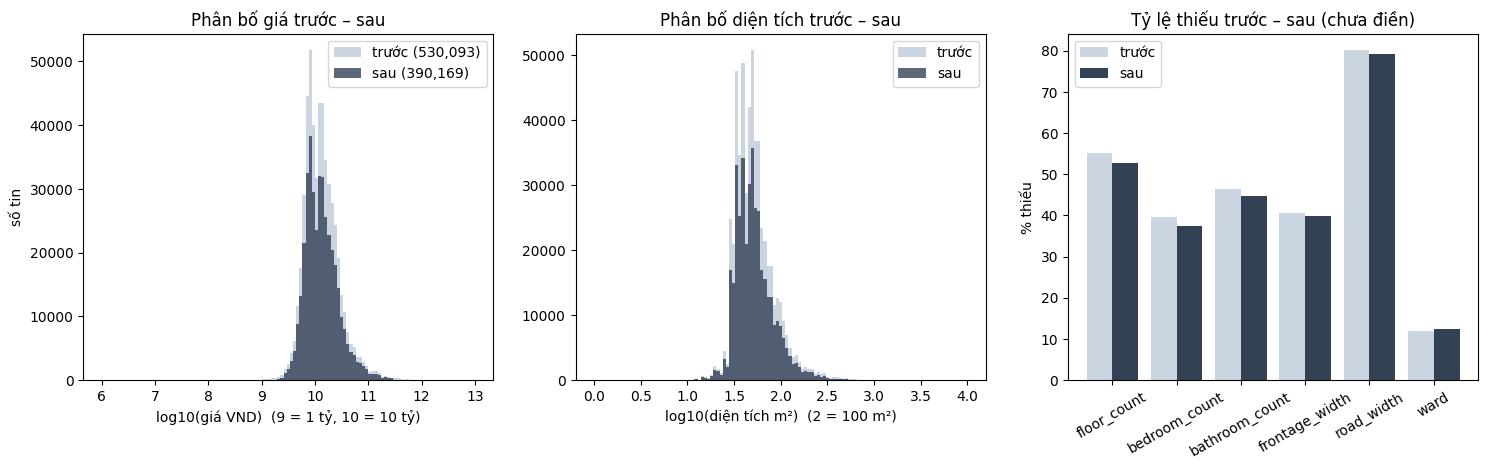

Nhận xét:
• Trước xử lý giá trải từ 3,250,000 đến 2,424,000 tỷ VND (gồm giá nhập sai đơn vị và giá phi thực tế); sau xử lý còn 0.7–300 tỷ, đuôi trái (giá < 300 triệu) biến mất.
• Diện tích max giảm từ 50,500 m² xuống 1,000 m²; trung vị gần như không đổi (49 → 49 m²) → lọc chỉ cắt đuôi, không làm lệch phần lõi dữ liệu.
• Tỷ lệ thiếu trước → sau: floor_count 55% → 53%, bedroom_count 40% → 37%, bathroom_count 46% → 45%, frontage_width 41% → 40%, road_width 80% → 79%, ward 12% → 12%. Thay đổi đến từ việc bỏ tin trùng/ngoại lai và đặt NaN cho giá trị phi lý; làm sạch KHÔNG điền khuyết — việc điền nằm trong Pipeline (median + cờ thiếu) để chỉ học từ tập train.


In [17]:
def summary(d, name):
    p, a = d["price"].dropna(), d["area"].dropna()
    p = p[p > 0]; a = a[a > 0]
    return {"bộ dữ liệu": name, "số tin": len(d), "giá trung vị (tỷ)": p.median() / 1e9, "giá trung bình (tỷ)": p.mean() / 1e9,
            "giá max (tỷ)": p.max() / 1e9, "độ lệch (skew) của giá": p.skew(), "skew của log(giá)": np.log(p).skew(),
            "diện tích trung vị": a.median(), "diện tích max": a.max(),
            "% thiếu số tầng": d["floor_count"].isna().mean() * 100, "% thiếu mặt tiền": d["frontage_width"].isna().mean() * 100}
ba = pd.DataFrame([summary(before, "Trước (đã parse, chưa lọc)"), summary(clean, "Sau xử lý")]).set_index("bộ dữ liệu").T
display(ba.round(3))
save_table(ba.round(4), "truoc_sau_tom_tat")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
pb = before["price"][before["price"] > 0]
bins = np.linspace(6, 13, 120)
axes[0].hist(np.log10(pb), bins=bins, color="#cbd5e1", label=f"trước ({len(pb):,})")
axes[0].hist(np.log10(clean["price"]), bins=bins, color="#334155", alpha=0.8, label=f"sau ({len(clean):,})")
axes[0].set(xlabel="log10(giá VND)  (9 = 1 tỷ, 10 = 10 tỷ)", ylabel="số tin", title="Phân bố giá trước – sau"); axes[0].legend()
ab = before["area"][before["area"] > 0]
bins = np.linspace(0, 4, 120)
axes[1].hist(np.log10(ab), bins=bins, color="#cbd5e1", label="trước")
axes[1].hist(np.log10(clean["area"]), bins=bins, color="#334155", alpha=0.8, label="sau")
axes[1].set(xlabel="log10(diện tích m²)  (2 = 100 m²)", title="Phân bố diện tích trước – sau"); axes[1].legend()
cols = ["floor_count", "bedroom_count", "bathroom_count", "frontage_width", "road_width", "ward"]
mb = before[cols].isna().mean() * 100; mb["ward"] = before["ward"].astype(str).str.strip().isin(["", "nan", "None"]).mean() * 100
mc = clean[cols].isna().mean() * 100; mc["ward"] = clean["ward"].astype(str).str.strip().isin(["", "nan", "None"]).mean() * 100
x = np.arange(len(cols))
axes[2].bar(x - 0.2, mb.values, 0.4, color="#cbd5e1", label="trước"); axes[2].bar(x + 0.2, mc.values, 0.4, color="#334155", label="sau")
axes[2].set_xticks(x, cols, rotation=30); axes[2].set(ylabel="% thiếu", title="Tỷ lệ thiếu trước – sau (chưa điền)"); axes[2].legend()
save_fig(fig, "01_truoc_sau")

print("Nhận xét:")
print(f"• Trước xử lý giá trải từ {pb.min():,.0f} đến {pb.max()/1e9:,.0f} tỷ VND (gồm giá nhập sai đơn vị và giá phi thực tế); "
      f"sau xử lý còn {clean['price'].min()/1e9:.1f}–{clean['price'].max()/1e9:.0f} tỷ, đuôi trái (giá < 300 triệu) biến mất.")
print(f"• Diện tích max giảm từ {ab.max():,.0f} m² xuống {clean['area'].max():,.0f} m²; trung vị gần như không đổi "
      f"({ab.median():.0f} → {clean['area'].median():.0f} m²) → lọc chỉ cắt đuôi, không làm lệch phần lõi dữ liệu.")
print("• Tỷ lệ thiếu trước → sau: " + ", ".join(f"{c} {mb[c]:.0f}% → {mc[c]:.0f}%" for c in cols)
      + ". Thay đổi đến từ việc bỏ tin trùng/ngoại lai và đặt NaN cho giá trị phi lý; làm sạch KHÔNG điền khuyết — "
      "việc điền nằm trong Pipeline (median + cờ thiếu) để chỉ học từ tập train.")

## 4. Phân bố các đặc trưng chính và nhãn (dữ liệu sạch)

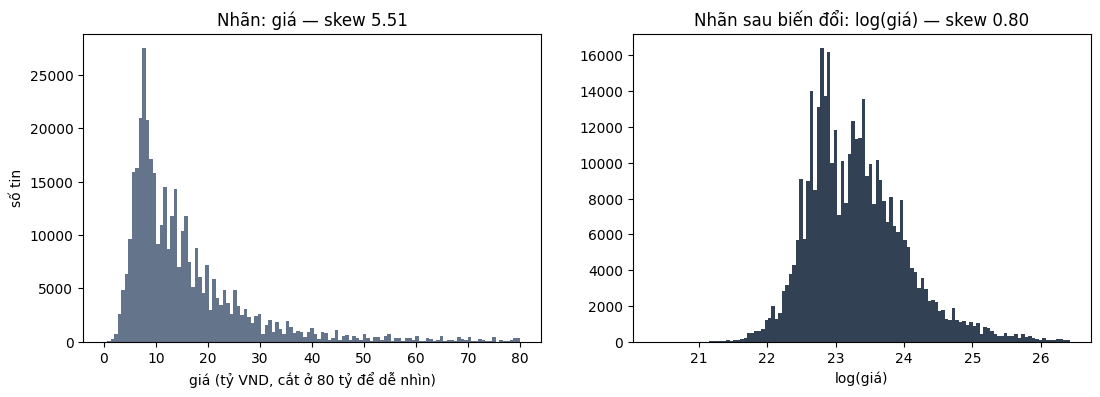

Nhận xét: giá lệch phải rất mạnh (skew 5.51 ), trung vị 12.4 tỷ nhưng trung bình 18.1 tỷ → dùng log(giá) làm biến mục tiêu; sau biến đổi skew còn 0.8 (gần đối xứng), phù hợp giả định sai số của hồi quy tuyến tính.


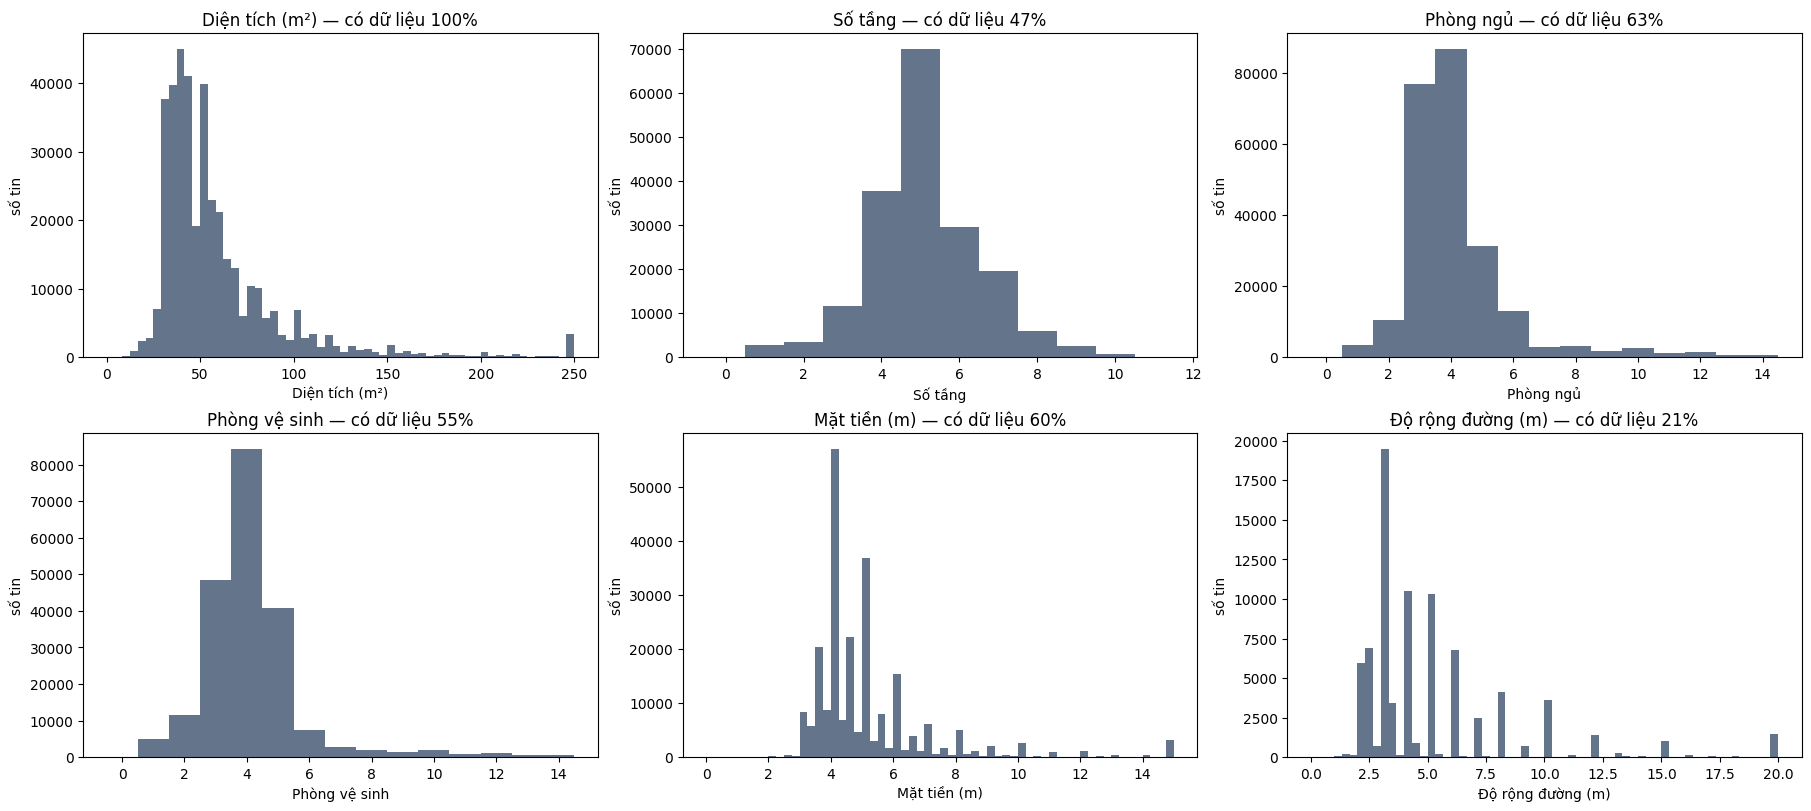

Nhận xét (số liệu in kèm):
• Diện tích (m²): n=390,169, trung vị 49, IQR 38–66, skew 5.04
• Số tầng: n=184,278, trung vị 5, IQR 4–6, skew 0.22
• Phòng ngủ: n=243,899, trung vị 4, IQR 3–5, skew 3.98
• Phòng vệ sinh: n=215,915, trung vị 4, IQR 3–5, skew 4.03
• Mặt tiền (m): n=234,414, trung vị 4.5, IQR 4–5.5, skew 6.54
• Độ rộng đường (m): n=81,611, trung vị 4, IQR 3–6, skew 8.15
→ Lệch phải mạnh (skew > 2): Diện tích (m²), Phòng ngủ, Phòng vệ sinh, Mặt tiền (m), Độ rộng đường (m) → dùng log(diện tích); các biến còn lại chuẩn hoá trong pipeline (cắt trần giá trị phi lý ở notebook 01).
→ Giá trị phổ biến nhất: diện tích 40 m², 5 tầng, 4 phòng ngủ — kiểu 'nhà ống' điển hình của Hà Nội.
→ Tỷ lệ thiếu của các biến phụ từ 37% đến 79% → cần cờ thiếu để mô hình phân biệt 'không ghi' với giá trị thật.


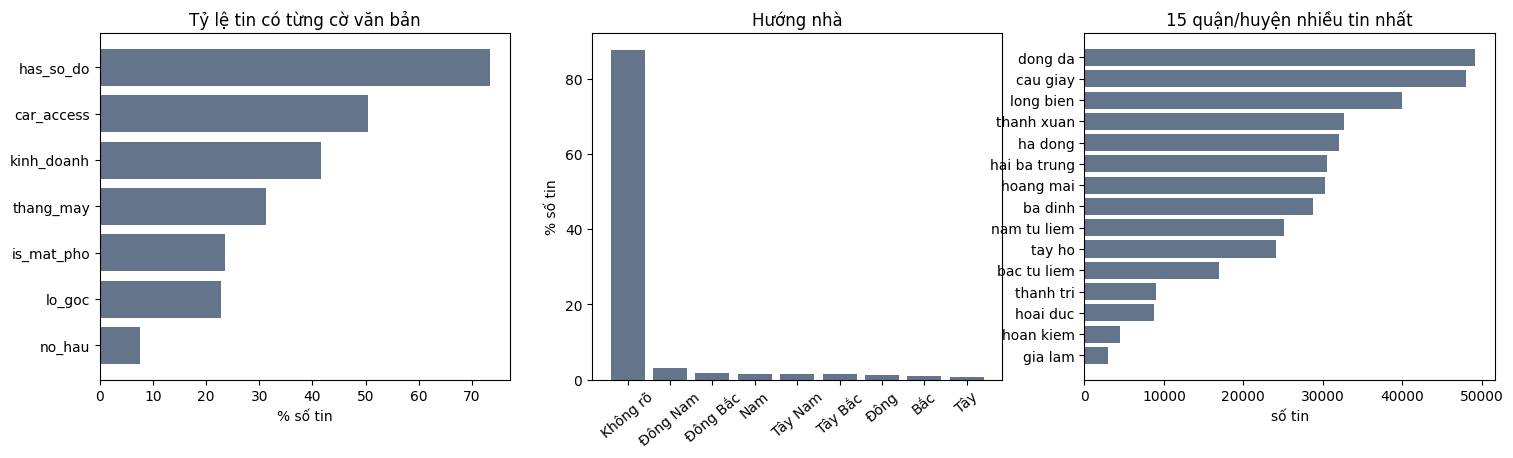

Nhận xét:
• Sổ đỏ/sổ hồng 73%, ô tô vào 51%, kinh doanh 42%, thang máy 31%, nở hậu 8% → cờ hiếm nhất vẫn có 29,799 tin, đủ để ước lượng hệ số.
• Hướng nhà 'Không rõ' chiếm 88% → biến này mang ít thông tin (ablation ở notebook 04 xác nhận).
• 6 quận nhiều tin nhất chiếm 60% số tin; 5 quận/huyện có dưới 30 tin → mất cân bằng địa bàn: gộp nhóm hiếm khi one-hot và báo cáo sai số theo quận.


In [18]:
def describe_skew(s):
    s = s.dropna()
    return f"n={len(s):,}, trung vị {s.median():g}, IQR {s.quantile(.25):g}–{s.quantile(.75):g}, skew {s.skew():.2f}"

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(clean["price"] / 1e9, bins=np.linspace(0, 80, 120), color="#64748b")
axes[0].set(xlabel="giá (tỷ VND, cắt ở 80 tỷ để dễ nhìn)", ylabel="số tin", title=f"Nhãn: giá — skew {clean['price'].skew():.2f}")
axes[1].hist(np.log(clean["price"]), bins=120, color="#334155")
axes[1].set(xlabel="log(giá)", title=f"Nhãn sau biến đổi: log(giá) — skew {np.log(clean['price']).skew():.2f}")
save_fig(fig, "02_phan_bo_nhan")
print("Nhận xét: giá lệch phải rất mạnh (skew", round(clean["price"].skew(), 2), "), trung vị", round(clean["price"].median() / 1e9, 1),
      "tỷ nhưng trung bình", round(clean["price"].mean() / 1e9, 1), "tỷ → dùng log(giá) làm biến mục tiêu; sau biến đổi skew còn",
      round(np.log(clean["price"]).skew(), 2), "(gần đối xứng), phù hợp giả định sai số của hồi quy tuyến tính.")

NUMS = [("area", "Diện tích (m²)", (0, 250)), ("floor_count", "Số tầng", (0, 12)), ("bedroom_count", "Phòng ngủ", (0, 15)),
        ("bathroom_count", "Phòng vệ sinh", (0, 15)), ("frontage_width", "Mặt tiền (m)", (0, 15)), ("road_width", "Độ rộng đường (m)", (0, 20))]
fig, axes = plt.subplots(2, 3, figsize=(18, 8), layout="constrained")   # tự giãn để nhãn trục không đè tiêu đề hàng dưới
for ax, (c, lab, rg) in zip(axes.ravel(), NUMS):
    s = clean[c].dropna()
    discrete = c in ("floor_count", "bedroom_count", "bathroom_count")
    bins = np.arange(rg[0], rg[1] + 1) - 0.5 if discrete else 60
    ax.hist(s.clip(*rg), bins=bins, range=None if discrete else rg, color="#64748b")
    ax.set(title=f"{lab} — có dữ liệu {len(s)/len(clean)*100:.0f}%", xlabel=lab, ylabel="số tin")
save_fig(fig, "03_phan_bo_dac_trung_so")
print("Nhận xét (số liệu in kèm):")
for c, lab, _ in NUMS:
    print(f"• {lab}: {describe_skew(clean[c])}")
sk = {c: clean[c].skew() for c, _, _ in NUMS}
strong = [lab for c, lab, _ in NUMS if sk[c] > 2]
print(f"→ Lệch phải mạnh (skew > 2): {', '.join(strong) or 'không có'} → dùng log(diện tích); các biến còn lại chuẩn hoá trong pipeline (cắt trần giá trị phi lý ở notebook 01).")
print(f"→ Giá trị phổ biến nhất: diện tích {clean['area'].mode().iat[0]:g} m², {clean['floor_count'].mode().iat[0]:g} tầng, "
      f"{clean['bedroom_count'].mode().iat[0]:g} phòng ngủ — kiểu 'nhà ống' điển hình của Hà Nội.")
mr = {lab: clean[c].isna().mean() * 100 for c, lab, _ in NUMS if c != "area"}
print(f"→ Tỷ lệ thiếu của các biến phụ từ {min(mr.values()):.0f}% đến {max(mr.values()):.0f}% → cần cờ thiếu để mô hình phân biệt 'không ghi' với giá trị thật.")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fr = (clean[TEXT_FLAGS].mean() * 100).sort_values()
axes[0].barh(fr.index, fr.values, color="#64748b"); axes[0].set(xlabel="% số tin", title="Tỷ lệ tin có từng cờ văn bản")
hd = clean["house_direction"].value_counts(normalize=True) * 100
axes[1].bar(hd.index, hd.values, color="#64748b"); axes[1].tick_params(axis="x", rotation=40); axes[1].set(ylabel="% số tin", title="Hướng nhà")
dk = clean["district_key"].value_counts().head(15)[::-1]
axes[2].barh(dk.index, dk.values, color="#64748b"); axes[2].set(xlabel="số tin", title="15 quận/huyện nhiều tin nhất")
save_fig(fig, "04_phan_bo_dac_trung_phan_loai")
print("Nhận xét:")
print(f"• Sổ đỏ/sổ hồng {fr['has_so_do']:.0f}%, ô tô vào {fr['car_access']:.0f}%, kinh doanh {fr['kinh_doanh']:.0f}%, thang máy {fr['thang_may']:.0f}%, "
      f"nở hậu {fr['no_hau']:.0f}% → cờ hiếm nhất vẫn có {fr.min()/100*len(clean):,.0f} tin, đủ để ước lượng hệ số.")
print(f"• Hướng nhà 'Không rõ' chiếm {hd.get('Không rõ', 0):.0f}% → biến này mang ít thông tin (ablation ở notebook 04 xác nhận).")
vc = clean["district_key"].value_counts()
print(f"• 6 quận nhiều tin nhất chiếm {vc.head(6).sum()/vc.sum()*100:.0f}% số tin; {(vc < 30).sum()} quận/huyện có dưới 30 tin → mất cân bằng địa bàn: "
      "gộp nhóm hiếm khi one-hot và báo cáo sai số theo quận.")

## 5. Quan hệ giữa đặc trưng và giá

,tỷ lệ tin có (%),giá trung vị có / không,đơn giá trung vị có / không
kinh_doanh,41.659,1.811,1.370
thang_may,31.269,1.714,1.312
is_mat_pho,23.603,1.600,1.286
car_access,50.531,1.333,1.147
lo_goc,22.830,1.131,1.071
has_so_do,73.486,1.096,1.056
no_hau,7.637,1.049,1.011


Đã lưu: D:\HocMay_GiaNha_KT1/survey/01b\quan_he_co_van_ban_voi_gia.csv


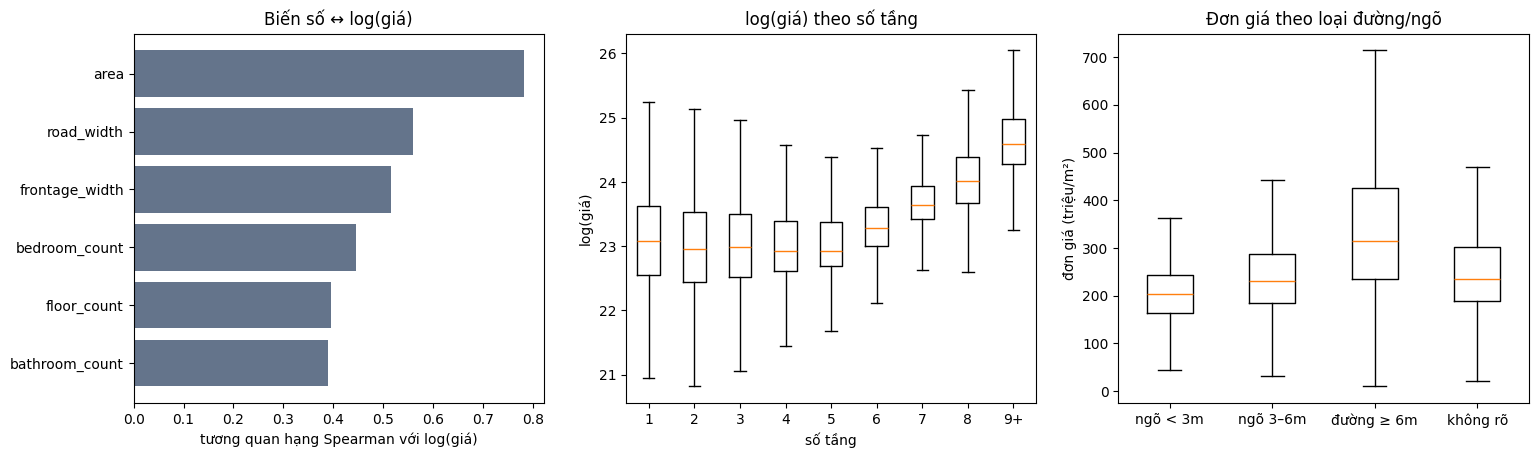

Nhận xét (≥ 3 nhận xét cho xây dựng mô hình):
1. Diện tích có tương quan hạng mạnh nhất với giá (ρ = 0.78); các biến kích thước khác chỉ 0.39–0.56 → diện tích là đặc trưng chính; Lasso chọn log(diện tích) đầu tiên.
2. Giá trung vị theo số tầng (tỷ): 1 tầng: 10.5, 2 tầng: 9.4, 3 tầng: 9.7, 4 tầng: 9.1, 5 tầng: 9.0, 6 tầng: 13.0, 7 tầng: 18.5, 8 tầng: 26.7, 9+ tầng: 47.8 → nếu đường này phẳng ở 1–5 tầng rồi tăng vọt từ 6 tầng (toà nhà có thang máy cho thuê), quan hệ KHÔNG tuyến tính: mô hình tuyến tính chỉ nắm được một phần, mô hình cây (Gradient Boosting) có lợi thế.
3. Đơn giá trung vị theo loại đường: ngõ < 3m ≈ 204, ngõ 3–6m ≈ 230, đường ≥ 6m ≈ 314 triệu/m² → giá nhảy bậc theo loại đường: rời rạc hoá độ rộng đường thành 'loại đường' là hợp lý.
4. Cờ văn bản mang tín hiệu giá: kinh doanh ×1.37, thang máy ×1.31, mặt phố ×1.29 đơn giá; nở hậu gần như không khác (×1.01) → Lasso có thể loại cờ này.
5. Phòng ngủ và phòng vệ sinh tương quan rất cao với nhau (~0,95, xem ma trận tương quan no

In [19]:
lp = np.log(clean["price"])
sp = clean[[c for c, _, _ in NUMS]].corrwith(lp, method="spearman").sort_values()
flag_eff = pd.DataFrame({"tỷ lệ tin có (%)": clean[TEXT_FLAGS].mean() * 100,
                         "giá trung vị có / không": [clean.loc[clean[f] == 1, "price"].median() / clean.loc[clean[f] == 0, "price"].median() for f in TEXT_FLAGS],
                         "đơn giá trung vị có / không": [clean.loc[clean[f] == 1, "unit_price"].median() / clean.loc[clean[f] == 0, "unit_price"].median() for f in TEXT_FLAGS]}).round(3)
display(flag_eff.sort_values("đơn giá trung vị có / không", ascending=False))
save_table(flag_eff, "quan_he_co_van_ban_voi_gia")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].barh(sp.index, sp.values, color="#64748b")
axes[0].set(xlabel="tương quan hạng Spearman với log(giá)", title="Biến số ↔ log(giá)")
fc = clean["floor_count"].clip(upper=9)
grp = [lp[fc == k] for k in range(1, 10)]
axes[1].boxplot(grp, showfliers=False); axes[1].set_xticks(range(1, 10), [str(k) if k < 9 else "9+" for k in range(1, 10)])
axes[1].set(xlabel="số tầng", ylabel="log(giá)", title="log(giá) theo số tầng")
order = ["ngo_nho_<3m", "ngo_oto_3-6m", "duong_lon_>=6m", "unknown"]
up = [clean.loc[clean["road_type"] == r, "unit_price"] / 1e6 for r in order]
axes[2].boxplot(up, showfliers=False); axes[2].set_xticks(range(1, 5), ["ngõ < 3m", "ngõ 3–6m", "đường ≥ 6m", "không rõ"])
axes[2].set(ylabel="đơn giá (triệu/m²)", title="Đơn giá theo loại đường/ngõ")
save_fig(fig, "05_quan_he_dac_trung_gia")

med_floor = (clean.groupby(fc)["price"].median() / 1e9).reindex(range(1, 10))
med_road = clean.groupby("road_type")["unit_price"].median() / 1e6
print("Nhận xét (≥ 3 nhận xét cho xây dựng mô hình):")
print(f"1. Diện tích có tương quan hạng mạnh nhất với giá (ρ = {sp['area']:.2f}); các biến kích thước khác chỉ {sp.drop('area').min():.2f}–{sp.drop('area').max():.2f} "
      "→ diện tích là đặc trưng chính; Lasso chọn log(diện tích) đầu tiên.")
print(f"2. Giá trung vị theo số tầng (tỷ): " + ", ".join(f"{k}{'+' if k == 9 else ''} tầng: {v:.1f}" for k, v in med_floor.dropna().items())
      + " → nếu đường này phẳng ở 1–5 tầng rồi tăng vọt từ 6 tầng (toà nhà có thang máy cho thuê), quan hệ KHÔNG tuyến tính: "
      "mô hình tuyến tính chỉ nắm được một phần, mô hình cây (Gradient Boosting) có lợi thế.")
med_road = med_road.reindex(order)
print(f"3. Đơn giá trung vị theo loại đường: ngõ < 3m ≈ {med_road.iloc[0]:.0f}, ngõ 3–6m ≈ {med_road.iloc[1]:.0f}, "
      f"đường ≥ 6m ≈ {med_road.iloc[2]:.0f} triệu/m² → giá nhảy bậc theo loại đường: rời rạc hoá độ rộng đường thành 'loại đường' là hợp lý.")
e = flag_eff["đơn giá trung vị có / không"]
print(f"4. Cờ văn bản mang tín hiệu giá: kinh doanh ×{e['kinh_doanh']:.2f}, thang máy ×{e['thang_may']:.2f}, mặt phố ×{e['is_mat_pho']:.2f} đơn giá; "
      f"nở hậu gần như không khác (×{e['no_hau']:.2f}) → Lasso có thể loại cờ này.")
print("5. Phòng ngủ và phòng vệ sinh tương quan rất cao với nhau (~0,95, xem ma trận tương quan notebook 01) → đa cộng tuyến: "
      "lý do so sánh Ridge/Lasso/Elastic Net.")